# D02-KM — K-Means trên RFM + AOV + Diversity với winsorization P95 (cap → log1p + Standard + PCA 90%)

Thí nghiệm **D02-KM** (người chạy: Nguyên) theo chiến lược model. So với D01, **chỉ đổi ngưỡng cap từ P99 xuống P95**: cắt các giá trị lớn hơn phân vị 95 của Frequency, Monetary, AOV và Diversity về đúng ngưỡng đó, giữ nguyên Recency và không xóa khách nào. Pipeline: làm sạch → 5 feature → **cap P95** → `log1p` → StandardScaler → PCA giữ ≥ 90% phương sai → K-Means. Mục đích: đo xem cap mạnh hơn có làm đổi cách chia khách so với D01 hay không.

Dữ liệu, seed, lưới k và quy tắc chọn k (Silhouette lớn nhất) giữ nguyên như các thí nghiệm K-Means khác (A02, B02, C02) và như K-Means của Thuận ở nhánh D. D01-KM chưa có trong repo nên được dựng lại ngay trong notebook để so cùng điều kiện (D01 dùng P99, cùng ngưỡng Thuận đã dùng cho D04 và E02–E04).

## Params

In [1]:
FEATURES = ["Recency", "Frequency", "Monetary", "AOV", "Diversity"]
CAP_FEATURES = ["Frequency", "Monetary", "AOV", "Diversity"]   # cap các biến này; Recency giữ nguyên
CAP_Q = 95                    # D02: P95 (D01 dùng P99, D03 dùng P99.5)
PCA_VAR = 0.90                # giữ ít nhất 90% phương sai (giống C01, D01)
K_GRID = range(2, 11)         # quét k = 2..10 (giống A02-KM .. C02-KM)
RANDOM_STATE = 42
N_INIT = 20

## Import thư viện và đọc dữ liệu

In [2]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, RobustScaler, FunctionTransformer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

def find(rel):
    # Tự tìm file trong repo, không phụ thuộc nơi mở notebook
    return next(c for p in [Path.cwd(), *Path.cwd().parents]
                for c in (p / rel, p / "project" / rel) if c.exists())

# Dùng chung file đặc trưng của nhóm (cùng nguồn với A01..D01), không sao chép thêm
DATA = find("notebooks/02_baseline_kmeans/12-11-2026-hieu-kmeans/data/customer_features.csv")
FIG, OUT = Path("figures"), Path("data")
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)

# AOV = avg_order_value, Diversity = n_stock_codes (số mã hàng khác nhau của khách)
df = pd.read_csv(DATA, dtype={"CustomerID": "string"}).rename(columns={"avg_order_value": "AOV", "n_stock_codes": "Diversity"})
X = df[FEATURES].astype(float)
assert df["CustomerID"].is_unique and X.notna().all().all() and (X >= 0).all().all()   # log1p cần X >= 0
assert np.allclose(df["AOV"], df["Monetary"] / df["Frequency"], atol=0.01)              # AOV = Monetary / Frequency
print("Dữ liệu đầu vào:", X.shape)
X.describe().round(2)

Dữ liệu đầu vào: (4327, 5)


,Recency,Frequency,Monetary,AOV,Diversity
count,4327.00,4327.00,4327.00,4327.00,4327.00
mean,93.04,4.25,1944.95,372.40,61.49
std,99.98,7.64,8441.89,466.49,85.31
min,1.00,1.00,2.90,2.90,1.00
25%,18.00,1.00,301.52,175.47,16.00
50%,51.00,2.00,657.90,286.70,35.00
75%,143.00,5.00,1624.10,421.99,77.00
max,374.00,206.00,278748.02,14844.77,1784.00


**Nhận xét:** 4.327 khách, 5 feature, không thiếu giá trị, không có giá trị âm. Cùng tệp đặc trưng 4.327 khách với các thí nghiệm A–D. Đuôi phải rất dài (Monetary lớn nhất 278.748 so với trung vị khoảng 658; Frequency lớn nhất 206 so với trung vị 2), là lý do nhánh D thử cắt đuôi ở cấp khách.

## Winsorization P95 (cap)

Ngưỡng cap = phân vị 95 của từng biến trong `CAP_FEATURES`; giá trị lớn hơn ngưỡng bị kéo về ngưỡng. Recency không cap (ngưỡng vô cực). Cap áp dụng **trước** `log1p`, trên giá trị gốc.

In [3]:
caps = X.quantile(CAP_Q / 100)
caps[[c for c in FEATURES if c not in CAP_FEATURES]] = np.inf        # Recency giữ nguyên
capped = X.gt(caps, axis=1)
X_cap = X.clip(upper=caps, axis=1)

cap_report = pd.DataFrame({
    "cap": caps.replace(np.inf, np.nan).round(2),
    "customers_capped": capped.sum(),
    "customers_capped_pct": (100 * capped.mean()).round(2),
    "value_capped_pct": (100 * (X - X_cap).sum() / X.sum()).round(2),
})
n_capped = int(capped.any(axis=1).sum())
print(f"Khách bị cap ở ít nhất 1 biến: {n_capped} ({100 * n_capped / len(X):.2f}%) | số khách sau cap: {len(X_cap)} (không xóa khách nào)")
print("Monetary lớn nhất: ", round(X["Monetary"].max(), 2), "->", round(X_cap["Monetary"].max(), 2))
skew = pd.DataFrame({"skew_raw": X.skew(), "skew_sau_cap": X_cap.skew(),
                     "skew_cap_log1p": np.log1p(X_cap).skew(), "skew_log1p_khong_cap (C01)": np.log1p(X).skew()}).round(2)
print(); print(cap_report.to_string()); print(); print(skew.to_string())

Khách bị cap ở ít nhất 1 biến: 527 (12.18%) | số khách sau cap: 4327 (không xóa khách nào)
Monetary lớn nhất:  278748.02 -> 5698.42

               cap  customers_capped  customers_capped_pct  value_capped_pct
Recency        NaN                 0                  0.00              0.00
Frequency    13.00               205                  4.74             15.49
Monetary   5698.42               217                  5.02             34.41
AOV         909.41               217                  5.02             10.52
Diversity   204.00               215                  4.97              9.38

           skew_raw  skew_sau_cap  skew_cap_log1p  skew_log1p_khong_cap (C01)
Recency        1.25          1.25           -0.33                       -0.33
Frequency     11.95          1.58            0.69                        1.21
Monetary      21.04          1.78           -0.08                        0.35
AOV           11.94          1.20           -0.56                       -0.00
Diversity     

**Nhận xét:** Ngưỡng P95 là Frequency 13, Monetary 5.698, AOV 909, Diversity 204. Cap mạnh hơn D01 nhiều: **527 khách (12,18%)** bị cap ở ít nhất một biến (mỗi biến khoảng 5% khách), và phần giá trị bị cắt là **34,41% tổng Monetary**, 15,49% Frequency, 10,52% AOV và 9,38% Diversity (D01 ở P99 chỉ cắt 21,62% Monetary và cap 116 khách). Độ lệch sau cap và `log1p` còn nhỏ (Frequency 0,69; Monetary −0,08; AOV −0,56; Diversity −0,40). Không khách nào bị xóa: vẫn đủ 4.327 khách.

## Chuẩn hóa và PCA giữ 90% phương sai

In [4]:
def make_prep(caps_values, scaler=None, n_components=None):
    steps = [("cap", FunctionTransformer(np.clip, kw_args={"a_min": None, "a_max": caps_values})),
             ("log1p", FunctionTransformer(np.log1p)),
             ("scaler", scaler if scaler is not None else StandardScaler())]
    if n_components is not None:
        steps.append(("pca", PCA(n_components=n_components, svd_solver="full", random_state=RANDOM_STATE)))
    return Pipeline(steps)

def build_space(caps_values, scaler=None):
    Xs = make_prep(caps_values, scaler).fit_transform(X.values)
    ev = PCA(svd_solver="full").fit(Xs).explained_variance_ratio_
    cum = np.cumsum(ev)
    n = int(np.searchsorted(cum, PCA_VAR) + 1)
    pre = make_prep(caps_values, scaler, n).fit(X.values)
    return pre, pre.transform(X.values), ev, cum, n

caps_values = caps.to_numpy()
prep, Z, ev, cum, n_pc = build_space(caps_values)

print("Phương sai từng PC:", ev.round(4))
print("Phương sai tích lũy:", cum.round(4))
print(f"Số PC giữ lại: {n_pc} / {len(FEATURES)} (phương sai giữ {cum[n_pc-1]:.2%})")
pd.DataFrame(prep["pca"].components_, index=[f"PC{i+1}" for i in range(n_pc)], columns=FEATURES).round(3)

Phương sai từng PC: [0.6244 0.202  0.0987 0.0727 0.0022]
Phương sai tích lũy: [0.6244 0.8264 0.9251 0.9978 1.    ]
Số PC giữ lại: 3 / 5 (phương sai giữ 92.51%)


,Recency,Frequency,Monetary,AOV,Diversity
PC1,-0.371,0.472,0.541,0.348,0.475
PC2,0.531,-0.375,0.176,0.738,0.047
PC3,0.753,0.429,0.093,-0.367,0.325


**Nhận xét:** Vẫn cần **3 PC** trên 5 biến để vượt 90% (giữ 92,51%; D01 92,41%, C01 92,40%), nên PCA thực sự giảm chiều như ở C01 và D01. Cap P95 gần như không đổi số chiều cần giữ.

## Quét số cụm k

Chọn k theo **Silhouette lớn nhất** — cùng quy tắc các thí nghiệm K-Means khác. Mọi chỉ số tính trên `Z` (không gian mô hình được fit). Cột `min_cluster` là số khách của cụm nhỏ nhất.

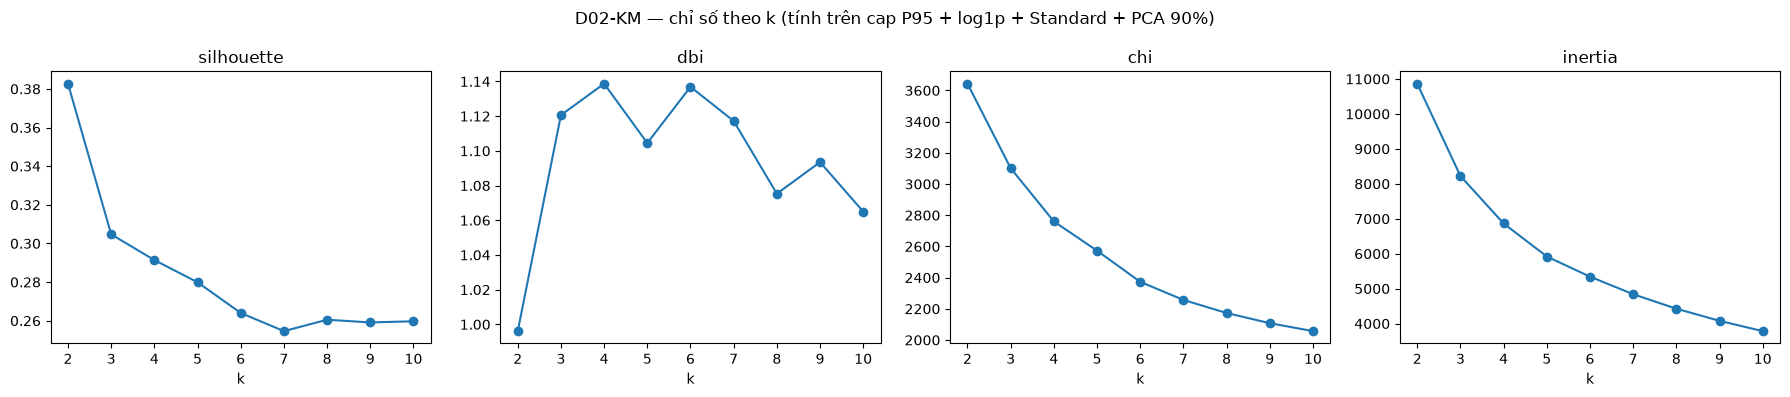

,k,silhouette,dbi,chi,inertia,min_cluster
0,2,0.3827,0.9961,3643.2,10863.7,1942
1,3,0.3047,1.1206,3101.4,8221.4,1100
2,4,0.2914,1.1387,2760.2,6865.0,995
3,5,0.2799,1.1045,2572.6,5919.9,701
4,6,0.2640,1.1369,2372.9,5343.4,541
5,7,0.2546,1.1172,2256.9,4840.8,449
6,8,0.2605,1.0753,2173.0,4426.2,428
7,9,0.2591,1.0935,2108.0,4080.1,146
8,10,0.2597,1.0650,2056.9,3784.8,137


In [5]:
def sweep(Zs):
    rows, labels_by_k = [], {}
    for k in K_GRID:
        km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=N_INIT).fit(Zs)
        labels_by_k[k] = km.labels_
        rows.append({"k": k,
                     "silhouette": round(silhouette_score(Zs, km.labels_), 4),
                     "dbi": round(davies_bouldin_score(Zs, km.labels_), 4),
                     "chi": round(calinski_harabasz_score(Zs, km.labels_), 1),
                     "inertia": round(km.inertia_, 1),
                     "min_cluster": int(np.bincount(km.labels_).min())})
    return pd.DataFrame(rows), labels_by_k

metrics, labels_by_k = sweep(Z)

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ["silhouette", "dbi", "chi", "inertia"]):
    ax.plot(metrics["k"], metrics[col], marker="o")
    ax.set_xlabel("k"); ax.set_title(col)
plt.suptitle("D02-KM — chỉ số theo k (tính trên cap P95 + log1p + Standard + PCA 90%)")
plt.tight_layout()
plt.savefig(FIG / "kmeans_metrics.png", dpi=150)
plt.show()
metrics

**Nhận xét:** Silhouette cao nhất ở **k = 2** (0,3827), rồi giảm xuống 0,3047 ở k = 3 và dao động quanh 0,25–0,29 ở k lớn hơn (thấp nhất 0,2546 ở k = 7). DBI thấp nhất cũng ở k = 2 (0,9961); CHI giảm đều từ 3.643,2 (k = 2) xuống 2.056,9 (k = 10). Cụm nhỏ nhất vẫn có ít nhất 137 khách ở mọi k = 2–10, không có cụm vài khách như A02-KM.

## Chọn k và huấn luyện mô hình cuối

In [6]:
best_k = int(metrics.loc[metrics["silhouette"].idxmax(), "k"])
print("k được chọn (Silhouette lớn nhất):", best_k)

model = Pipeline([("prep", make_prep(caps_values, None, n_pc)),
                  ("kmeans", KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=N_INIT))]).fit(X.values)
labels = model["kmeans"].labels_
assert np.allclose(model["prep"].transform(X.values), Z)         # pipeline cho đúng không gian đã quét
assert (labels == labels_by_k[best_k]).all()                     # và đúng nhãn đã quét ở trên
print(pd.Series(labels).value_counts().sort_index().rename("Số khách"))

k được chọn (Silhouette lớn nhất): 2
0    2385
1    1942
Name: Số khách, dtype: int64


**Nhận xét:** k = 2 chia 2.385 khách vào cụm 0 (55,1%) và 1.942 khách vào cụm 1 (44,9%) — hai nhóm cỡ gần bằng nhau, cùng kiểu chia như C02-KM (2.238 / 2.089).

## Hồ sơ cụm

Mô tả bằng trung vị **trên thang gốc, trước khi cap** (không phải log hay giá trị đã cắt). `Monetary_share_pct` là tỷ trọng tổng Monetary gốc của cụm.

In [7]:
def profile(lab):
    p = X.assign(cluster=lab).groupby("cluster").agg(
        customers=("Monetary", "size"), Recency=("Recency", "median"), Frequency=("Frequency", "median"),
        Monetary=("Monetary", "median"), AOV=("AOV", "median"), Diversity=("Diversity", "median"),
        Monetary_sum=("Monetary", "sum"))
    p["customer_share_pct"] = (100 * p["customers"] / len(X)).round(2)
    p["Monetary_share_pct"] = (100 * p["Monetary_sum"] / p["Monetary_sum"].sum()).round(2)
    return p.drop(columns="Monetary_sum")

prof = profile(labels)
prof.round(1)

,customers,Recency,Frequency,Monetary,AOV,Diversity,customer_share_pct,Monetary_share_pct
cluster,,,,,,,,
0,2385,107.0,1.0,320.5,212.6,19.0,55.1,11.1
1,1942,22.0,5.0,1787.1,358.4,82.5,44.9,88.9


**Nhận xét** (tên nhóm chỉ là cách gọi gợi ý từ trung vị):
- Cụm 1 (1.942 khách, 44,9%): Recency 22, Frequency 5, Monetary ≈ 1.787, AOV ≈ 358, Diversity 82,5 → **nhóm hoạt động: mua gần đây, thường xuyên, chi nhiều**; chiếm **88,9%** tổng Monetary.
- Cụm 0 (2.385 khách, 55,1%): Recency 107, Frequency 1, Monetary ≈ 321, AOV ≈ 213, Diversity 19 → **nhóm mua ít (thường một lần), đã lâu, chi thấp**; 11,1% Monetary.

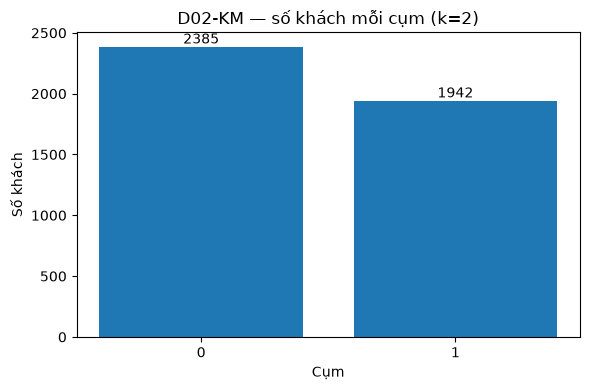

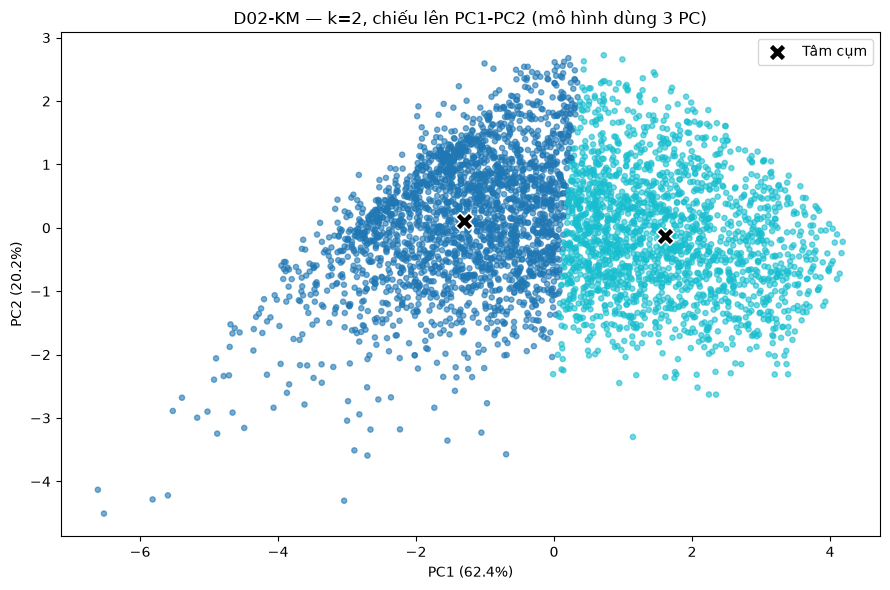

In [8]:
# Hình 1: số khách mỗi cụm
sizes = pd.Series(labels).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(sizes.index.astype(str), sizes.values); ax.bar_label(bars)
ax.set_xlabel("Cụm"); ax.set_ylabel("Số khách"); ax.set_title(f"D02-KM — số khách mỗi cụm (k={best_k})")
plt.tight_layout(); plt.savefig(FIG / "kmeans_cluster_distribution.png", dpi=150); plt.show()

# Hình 2: chiếu lên PC1-PC2 (mô hình dùng 3 PC)
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(Z[:, 0], Z[:, 1], c=labels, cmap="tab10", s=14, alpha=0.6)
ctr = model["kmeans"].cluster_centers_
ax.scatter(ctr[:, 0], ctr[:, 1], c="black", marker="X", s=160, edgecolors="white", linewidths=1.2, label="Tâm cụm")
ax.set_xlabel(f"PC1 ({prep['pca'].explained_variance_ratio_[0]:.1%})"); ax.set_ylabel(f"PC2 ({prep['pca'].explained_variance_ratio_[1]:.1%})")
ax.set_title(f"D02-KM — k={best_k}, chiếu lên PC1-PC2 (mô hình dùng {n_pc} PC)"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "kmeans_clusters_pca.png", dpi=150); plt.show()

**Nhận xét:** Hai cụm là hai nửa của cùng một đám mây liên tục, ngăn cách chủ yếu theo PC1; không có khoảng trống giữa chúng, nên đây là một đường cắt qua dải liên tục (hoạt động nhiều đến hoạt động ít) chứ không phải hai nhóm tách bạch.

## Kiểm chứng và đối chiếu D01, C01

Ba việc, tính lại bằng chính code ở trên: (1) tái hiện D04-KM của Thuận (cap P99 + RobustScaler) để kiểm tra bước cap và pipeline K-Means khớp nhóm; (2) dựng lại D01-KM (cap P99) để so riêng tác động của việc đổi ngưỡng cap; (3) dựng lại C01-KM (không cap) để thấy tác động chung của winsorization. ARI đo mức trùng nhóm giữa hai cách chia, 1,0 là giống hệt. Bảng còn tính Silhouette của mỗi cách chia trên **cả hai không gian**.

In [9]:
# (1) Tái hiện D04-KM của Thuận: cap P99 + RobustScaler(25-75), fit đúng k ông đã chọn
th = json.load(open(find("notebooks/02_baseline_kmeans/19-11-2026-thuan-kmeans-d04/data/kmeans_d04_params.json"), encoding="utf8"))
caps_p99 = X.quantile(0.99); caps_p99[[c for c in FEATURES if c not in CAP_FEATURES]] = np.inf
_, Z_d04, _, _, n_d04 = build_space(caps_p99.to_numpy(), RobustScaler(quantile_range=(25.0, 75.0)))
km_d04 = KMeans(n_clusters=th["k"], random_state=RANDOM_STATE, n_init=N_INIT).fit(Z_d04)
print(f"(1) D04-KM của Thuận: k={th['k']}, Silhouette={th['silhouette']:.4f}, Inertia={th['inertia']:,.2f}")
print(f"    Tính lại ở đây   : k={km_d04.n_clusters}, Silhouette={silhouette_score(Z_d04, km_d04.labels_):.4f}, "
      f"Inertia={km_d04.inertia_:,.2f}, {n_d04} PC")
print("    Khớp:", abs(silhouette_score(Z_d04, km_d04.labels_) - th["silhouette"]) < 1e-4 and abs(km_d04.inertia_ - th["inertia"]) < 0.01)

# (2) D01-KM dựng lại: cap P99, Standard
_, Z_d01, _, _, n_d01 = build_space(caps_p99.to_numpy())
metrics_d01, labels_by_k_d01 = sweep(Z_d01)
best_k_d01 = int(metrics_d01.loc[metrics_d01["silhouette"].idxmax(), "k"]); labels_d01 = labels_by_k_d01[best_k_d01]
# (3) C01-KM dựng lại: không cap
_, Z_c01, _, _, n_c01 = build_space(np.full(len(FEATURES), np.inf))
metrics_c01, labels_by_k_c01 = sweep(Z_c01)
best_k_c01 = int(metrics_c01.loc[metrics_c01["silhouette"].idxmax(), "k"]); labels_c01 = labels_by_k_c01[best_k_c01]
print(f"\n(2) D01-KM dựng lại: {n_d01} PC | k = {best_k_d01}   (3) C01-KM dựng lại: {n_c01} PC | k = {best_k_c01}")

ari_k = pd.DataFrame({"k": list(K_GRID),
                      "ARI_D02_vs_D01": [round(adjusted_rand_score(labels_by_k[k], labels_by_k_d01[k]), 4) for k in K_GRID],
                      "silhouette_D02": metrics["silhouette"].values, "silhouette_D01": metrics_d01["silhouette"].values,
                      "silhouette_C01": metrics_c01["silhouette"].values})
print("ARI giữa các cách chia ở k riêng của mỗi bên: D02-D01 =", round(adjusted_rand_score(labels, labels_d01), 4),
      "| D02-C01 =", round(adjusted_rand_score(labels, labels_c01), 4), "| D01-C01 =", round(adjusted_rand_score(labels_d01, labels_c01), 4))
ari_k

(1) D04-KM của Thuận: k=2, Silhouette=0.3648, Inertia=5,753.78


    Tính lại ở đây   : k=2, Silhouette=0.3648, Inertia=5,753.78, 3 PC


    Khớp: True



(2) D01-KM dựng lại: 3 PC | k = 2   (3) C01-KM dựng lại: 3 PC | k = 2
ARI giữa các cách chia ở k riêng của mỗi bên: D02-D01 = 0.9381 | D02-C01 = 0.9265 | D01-C01 = 0.9843


,k,ARI_D02_vs_D01,silhouette_D02,silhouette_D01,silhouette_C01
0,2,0.9381,0.3827,0.3770,0.3754
1,3,0.7061,0.3047,0.2849,0.2813
2,4,0.8631,0.2914,0.2775,0.2739
3,5,0.8767,0.2799,0.2727,0.2688
4,6,0.7227,0.2640,0.2591,0.2566
5,7,0.7568,0.2546,0.2476,0.2502
6,8,0.6597,0.2605,0.2531,0.2518
7,9,0.6756,0.2591,0.2508,0.2469
8,10,0.7106,0.2597,0.2517,0.2474


In [10]:
def row(name, cfg, n_components, m_row, lab):
    return {"Thí nghiệm": name, "Cấu hình": cfg, "Số PC": n_components, "k": int(m_row["k"]),
            "Silhouette": m_row["silhouette"], "DBI": m_row["dbi"], "CHI": m_row["chi"], "Inertia": m_row["inertia"],
            "Kích thước cụm": sorted(np.bincount(lab).tolist(), reverse=True),
            "Silhouette trên không gian D01": round(silhouette_score(Z_d01, lab), 4),
            "Silhouette trên không gian D02": round(silhouette_score(Z, lab), 4)}

cmp = pd.DataFrame([
    row("D02-KM", "cap P95 + log1p + Standard + PCA 90%", n_pc, metrics.loc[metrics.k == best_k].iloc[0], labels),
    row("D01-KM (dựng lại)", "cap P99 + log1p + Standard + PCA 90%", n_d01, metrics_d01.loc[metrics_d01.k == best_k_d01].iloc[0], labels_d01),
    row("C01-KM (dựng lại)", "không cap + log1p + Standard + PCA 90%", n_c01, metrics_c01.loc[metrics_c01.k == best_k_c01].iloc[0], labels_c01),
])
# Khách nào đổi nhóm khi cap mạnh hơn? (nhóm hoạt động = cụm có Monetary median cao hơn)
act02 = labels == profile(labels)["Monetary"].idxmax()
act01 = labels_d01 == profile(labels_d01)["Monetary"].idxmax()
n_move = int((act01 ^ act02).sum())
print(f"Số khách đổi nhóm giữa D01 và D02: {n_move} ({n_move / len(X):.1%})")
print("Bảng chéo (hàng: cụm D01, cột: cụm D02):")
print(pd.crosstab(pd.Series(labels_d01, name="D01"), pd.Series(labels, name="D02")).to_string())
groups = {"Hoạt động ở cả D01 và D02": act01 & act02, "Mua ít ở cả D01 và D02": ~act01 & ~act02,
          "D01 mua ít -> D02 hoạt động": ~act01 & act02, "D01 hoạt động -> D02 mua ít": act01 & ~act02}
movers = pd.DataFrame([{"Nhóm": n_, "Số khách": int(m.sum()), **X[m].median().round(1).to_dict()} for n_, m in groups.items()])
print(); print(movers.to_string(index=False)); print()
cmp

Số khách đổi nhóm giữa D01 và D02: 68 (1.6%)
Bảng chéo (hàng: cụm D01, cột: cụm D02):
D02     0     1
D01            
0       9  1883
1    2376    59

                       Nhóm  Số khách  Recency  Frequency  Monetary    AOV  Diversity
  Hoạt động ở cả D01 và D02      1883     20.0        5.0    1836.1  360.2       84.0
     Mua ít ở cả D01 và D02      2376    107.0        1.0     318.7  211.8       19.0
D01 mua ít -> D02 hoạt động        59     45.0        2.0     744.8  321.4       43.0
D01 hoạt động -> D02 mua ít         9    138.0        1.0    1837.9 1837.9       29.0



,Thí nghiệm,Cấu hình,Số PC,k,Silhouette,DBI,CHI,Inertia,Kích thước cụm,Silhouette trên không gian D01,Silhouette trên không gian D02
0,D02-KM,cap P95 + log1p + Standard + PCA 90%,3,2,0.3827,0.9961,3643.2,10863.7,"[2385, 1942]",0.3754,0.3827
1,D01-KM (dựng lại),cap P99 + log1p + Standard + PCA 90%,3,2,0.3770,1.0101,3476.5,11083.6,"[2435, 1892]",0.3770,0.3830
2,C01-KM (dựng lại),không cap + log1p + Standard + PCA 90%,3,2,0.3754,1.0147,3375.4,11227.5,"[2452, 1875]",0.3774,0.3831


**Nhận xét:**
- **Pipeline khớp nhóm:** tái hiện D04-KM của Thuận (cap P99 + RobustScaler) cho đúng k = 2, Silhouette 0,3648 và Inertia 5.753,78.
- **K-Means rất ít nhạy với mức cap:** cả D02 (P95), D01 (P99) và C01 (không cap) đều chọn k = 2 và chia khách theo cùng một ranh giới: ARI giữa D02 và D01 là 0,9381, giữa D01 và C01 là 0,9843, giữa D02 và C01 là 0,9265. Chỉ **68 khách (1,6%)** đổi nhóm giữa D01 và D02, dù P95 cắt tới 34,41% tổng Monetary và cap 12,18% khách. Đó là các khách sát ranh giới: 59 khách (Recency trung vị 45, Frequency 2, Monetary ≈ 745) chuyển lên nhóm hoạt động, và 9 khách chỉ mua một đơn lớn (Monetary bằng AOV ≈ 1.838, Recency 138) chuyển xuống nhóm mua ít.
- **Khác biệt tăng khi k lớn hơn:** ARI giữa D02 và D01 theo từng k dao động 0,66–0,94 (k = 2 cao nhất, k = 8 thấp nhất), nên cap có ảnh hưởng nhiều hơn khi chia nhỏ hơn hai nhóm.
- **Chất lượng cụm gần như không đổi:** trên cùng một không gian, hai cách chia (D01 và D02) có Silhouette chênh nhau dưới 0,002; Silhouette trên không gian riêng 0,3827 (D02), 0,3770 (D01), 0,3754 (C01) chỉ hơn kém nhau chút ít và không so trực tiếp được (khác không gian).
- **Nhiều khả năng `log1p` đã nén đuôi đủ cho K-Means** nên cap thêm ít tác dụng (ARI giữa D01 và C01 là 0,9843); thí nghiệm này chưa tách riêng được cơ chế đó, nên đây chỉ là giả thuyết. Ngược lại GMM ở cùng nhánh nhạy hơn nhiều (ARI giữa C01-GMM và D01-GMM chỉ 0,4914).

## Lưu kết quả

In [11]:
pd.DataFrame({"CustomerID": df["CustomerID"], "cluster": labels}).to_csv(OUT / "kmeans_d02_labels.csv", index=False)
joblib.dump(model, "kmeans_model.pkl")

m = metrics.loc[metrics.k == best_k].iloc[0]
params = {"experiment": "D02-KM", "features": FEATURES, "feature_sources": {"AOV": "avg_order_value", "Diversity": "n_stock_codes"},
          "cap_percentile": CAP_Q, "cap_features": CAP_FEATURES,
          "caps": {k: (None if np.isinf(v) else float(v)) for k, v in caps.items()}, "customers_capped": n_capped,
          "transform": "log1p", "scaler": "StandardScaler",
          "pca_variance": PCA_VAR, "n_components": n_pc, "pca_variance_kept": float(cum[n_pc - 1]),
          "k": best_k, "n_customers": int(len(X)),
          "silhouette": float(m["silhouette"]), "dbi": float(m["dbi"]), "chi": float(m["chi"]), "inertia": float(m["inertia"]),
          "ari_vs_d01": round(float(adjusted_rand_score(labels, labels_d01)), 4),
          "ari_vs_c01": round(float(adjusted_rand_score(labels, labels_c01)), 4),
          "customers_changed_vs_d01": n_move,
          "kmeans_params": model["kmeans"].get_params()}
json.dump(params, open("kmeans_params.json", "w", encoding="utf8"), ensure_ascii=False, indent=2)
print("Đã lưu:", sorted(p.name for p in Path(".").iterdir() if p.is_file()), sorted(p.name for p in OUT.iterdir()))

Đã lưu: ['Working_details_KMeans_D02.xlsx', 'kmeans_d02.ipynb', 'kmeans_model.pkl', 'kmeans_params.json'] ['kmeans_d02_labels.csv']


## Working_details

Ghi bảng tóm tắt theo đúng bố cục `Working_details_KMeans_RFM.xlsx` của A01-KM (thiết lập, bảng theo k, bảng cụm), thêm bảng đối chiếu D01/C01 và sheet `Cap` (bảng ngưỡng cap).

In [12]:
from openpyxl import Workbook
from openpyxl.styles import Font

wb = Workbook(); ws = wb.active; ws.title = "KMeans_D02"
B = Font(name="Calibri", bold=True)
def put(cell, value, bold=False, fmt=None, sheet=None):
    sh = sheet or ws
    sh[cell] = value
    sh[cell].font = B if bold else Font(name="Calibri")
    if fmt: sh[cell].number_format = fmt

put("A1", "THÍ NGHIỆM K-MEANS — D02 (RFM + AOV + Diversity, cap P95, log1p, Standard, PCA 90%)", bold=True)
put("A2", "Trạng thái", bold=True)
put("B2", "Đã chạy xong; chỉ số tính trên Z (không gian đã fit). Khác D01 ở ngưỡng cap (P95 thay vì P99)")
for c, v in zip("ABDE", ["Thiết lập", "Giá trị", "Tham số khác", "Giá trị"]): put(f"{c}4", v, bold=True)
left = [("Feature", "Recency, Frequency, Monetary, AOV, Diversity"),
        ("Dữ liệu train", f"Z (cap P95 → log1p → Standard → PCA, {n_pc} PC)"),
        ("K được chọn", best_k), ("random_state", RANDOM_STATE), ("init", "k-means++"), ("n_init", N_INIT)]
right = [("max_iter", 300), ("tol", 0.0001), ("Tổng khách hàng", int(len(X))), ("Số cụm", best_k),
         ("PCA", f"90% → {n_pc}/{len(FEATURES)} PC (phương sai {cum[n_pc-1]:.2%})"),
         ("Winsorization", f"P{CAP_Q}: {n_capped} khách ({100*n_capped/len(X):.2f}%) bị cap; không xóa khách")]
for i, ((a, b), (d, e)) in enumerate(zip(left, right), start=5):
    put(f"A{i}", a); put(f"B{i}", b); put(f"D{i}", d); put(f"E{i}", e)
ws["E6"].number_format = "0.0000"

for c, v in zip("ABCDEF", ["k", "Silhouette", "DBI", "CHI", "Inertia", "Nhận xét"]): put(f"{c}12", v, bold=True)
for i, r in enumerate(metrics.itertuples(), start=13):
    put(f"A{i}", int(r.k)); put(f"B{i}", r.silhouette, fmt="0.0000"); put(f"C{i}", r.dbi, fmt="0.0000")
    put(f"D{i}", r.chi, fmt="0.00"); put(f"E{i}", r.inertia, fmt="0.00")
    note = "k được chọn (Silhouette lớn nhất)" if r.k == best_k else ""
    if r.min_cluster <= 5: note = (note + "; " if note else "") + f"cụm nhỏ nhất chỉ {r.min_cluster} khách"
    put(f"F{i}", note)

r0 = 13 + len(metrics) + 2
hdr = ["Cụm", "Nhóm khách hàng", "Số khách", "Tỷ lệ (%)", "Recency (median)", "Frequency (median)",
       "Monetary (median)", "AOV (median)", "Diversity (median)", "Tỷ trọng Monetary (%)"]
for c, v in zip("ABCDEFGHIJ", hdr): put(f"{c}{r0}", v, bold=True)
med = X.median()
def mo_ta(p):
    return ("Recency xa" if p["Recency"] > med["Recency"] else "Recency gần") + ", " + \
           ("Frequency cao" if p["Frequency"] > med["Frequency"] else "Frequency thấp") + ", " + \
           ("Monetary cao" if p["Monetary"] > med["Monetary"] else "Monetary thấp")
for j, (cl, p) in enumerate(prof.iterrows(), start=r0 + 1):
    put(f"A{j}", int(cl)); put(f"B{j}", mo_ta(p)); put(f"C{j}", int(p["customers"]))
    put(f"D{j}", float(p["customer_share_pct"]), fmt="0.00"); put(f"E{j}", float(p["Recency"]))
    put(f"F{j}", float(p["Frequency"])); put(f"G{j}", float(p["Monetary"]), fmt="0.00")
    put(f"H{j}", float(p["AOV"]), fmt="0.00"); put(f"I{j}", float(p["Diversity"]))
    put(f"J{j}", float(p["Monetary_share_pct"]), fmt="0.00")

r1 = r0 + len(prof) + 3
put(f"A{r1}", "Đối chiếu D01-KM và C01-KM (dựng lại; chỉ số tính trên không gian đã fit của từng thí nghiệm)", bold=True)
for c, v in zip("ABCDEFGHIJ", ["Thí nghiệm", "Cấu hình", "k", "Silhouette", "DBI", "CHI", "Inertia", "Kích thước cụm",
                                "Silhouette trên không gian D01", "Silhouette trên không gian D02"]):
    put(f"{c}{r1+1}", v, bold=True)
for j, r in enumerate(cmp.itertuples(index=False), start=r1 + 2):
    vals = [r[0], r[1], int(r[3]), float(r[4]), float(r[5]), float(r[6]), float(r[7]), str(r[8]), float(r[9]), float(r[10])]
    for c, v in zip("ABCDEFGHIJ", vals):
        put(f"{c}{j}", v, fmt="0.0000" if c in "DEIJ" else ("0.00" if c in "FG" else None))
base = r1 + 2 + len(cmp) + 1
put(f"A{base}", f"ARI ở k riêng: D02-D01 = {adjusted_rand_score(labels, labels_d01):.4f} | D02-C01 = {adjusted_rand_score(labels, labels_c01):.4f} | D01-C01 = {adjusted_rand_score(labels_d01, labels_c01):.4f}")
put(f"A{base+1}", f"ARI D02-D01 theo k = 2..10: {ari_k['ARI_D02_vs_D01'].min():.2f}–{ari_k['ARI_D02_vs_D01'].max():.2f}")
put(f"A{base+2}", f"Khách đổi nhóm giữa D01 và D02: {n_move} ({n_move / len(X):.1%})")
put(f"A{base+3}", f"Tái hiện D04-KM (Thuận, cap P99 + Robust): Silhouette {silhouette_score(Z_d04, km_d04.labels_):.4f}, Inertia {km_d04.inertia_:,.2f} (Thuận: {th['silhouette']:.4f}; {th['inertia']:,.2f})")
put(f"A{base+4}", "Silhouette/DBI/CHI của các thí nghiệm tính trên các không gian khác nhau nên không so trực tiếp; hai cột cuối là phép so cùng không gian.")

for col, w in zip("ABCDEFGHIJ", [16, 22, 17, 19, 20, 21, 25, 22, 22, 24]): ws.column_dimensions[col].width = w
ws.freeze_panes = "A5"

ws3 = wb.create_sheet("Cap")
for c, v in zip("ABCDE", ["Biến", f"Ngưỡng cap (P{CAP_Q})", "Số khách bị cap", "Tỷ lệ khách bị cap (%)", "Giá trị bị cắt (% tổng)"]):
    put(f"{c}1", v, bold=True, sheet=ws3)
for i, (feat, r) in enumerate(cap_report.iterrows(), start=2):
    put(f"A{i}", feat, sheet=ws3)
    put(f"B{i}", "không cap" if np.isnan(r["cap"]) else float(r["cap"]), fmt="0.00", sheet=ws3)
    put(f"C{i}", int(r["customers_capped"]), sheet=ws3); put(f"D{i}", float(r["customers_capped_pct"]), fmt="0.00", sheet=ws3)
    put(f"E{i}", float(r["value_capped_pct"]), fmt="0.00", sheet=ws3)
put(f"A{len(cap_report) + 3}", f"Khách bị cap ở ít nhất 1 biến: {n_capped} ({100 * n_capped / len(X):.2f}%); không xóa khách nào ({len(X)} khách còn nguyên).", sheet=ws3)
for col, w in zip("ABCDE", [14, 20, 18, 24, 24]): ws3.column_dimensions[col].width = w

wb.save("Working_details_KMeans_D02.xlsx")
print("Đã lưu Working_details_KMeans_D02.xlsx")

Đã lưu Working_details_KMeans_D02.xlsx


## Kết luận D02-KM

- **K-Means vẫn chọn k = 2** (Silhouette 0,3827; k = 3 chỉ 0,3047): nhóm hoạt động (1.942 khách, 44,9%) giữ 88,9% Monetary và nhóm mua ít (2.385 khách, 55,1%) giữ 11,1%. Cụm cân đối, cụm nhỏ nhất ≥ 137 khách ở mọi k.
- **Cap mạnh hơn (P95) hầu như không đổi cách chia so với D01 (P99):** ARI 0,9381 ở k = 2, chỉ 68 khách (1,6%) đổi nhóm, dù P95 cắt 34,41% tổng Monetary và cap 12,18% khách. So với C01 (không cap), ARI vẫn 0,9265. Nghĩa là với K-Means k = 2, winsorization không thêm thông tin đáng kể.
- **Pipeline kiểm chứng được:** tái hiện D04-KM của Thuận cho đúng k, Silhouette và Inertia.
- **Giới hạn:** K-Means theo Silhouette chỉ cắt dải khách liên tục thành "hoạt động" và "mua ít"; ảnh hưởng của cap lớn hơn ở k lớn (ARI D02 so với D01 xuống 0,66 ở k = 8) và ở GMM (ARI C01 so với D01 chỉ 0,4914). Silhouette không so trực tiếp được giữa các không gian khác nhau.
- **Bước kế tiếp:** D04-DB (cap P99 cộng RobustScaler) và E04-DB (cap P99, không PCA); D03-KM của An và D01-KM của Hiếu còn thiếu, và D01-KM dựng lại ở đây có thể dùng để đối chiếu.